# 1. Análise e preparação do dataset
A equipe deverá conhecer e organizar os dados antes de iniciar a modelagem. Essa etapa deverá contemplar:

- Identificação das classes e da quantidade de imagens por classe.
- Verificação de imagens corrompidas, duplicadas ou com problemas de rotulagem.
- Análise do balanceamento entre as classes.
- Apresentação de exemplos das imagens e das principais dificuldades do problema.
- Divisão dos dados em conjuntos de treinamento e teste, com justificativa da estratégia utilizada.
  -Imagens do mesmo objeto, indivíduo ou sequência, quando existentes, deverão permanecer no mesmo conjunto para evitar vazamento de dados.

In [77]:
# Importações 
from pathlib import Path
from collections import Counter
import pandas as pd
import cv2
import hashlib
import random
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## 1.1 - Identificação das classes e da quantidade de imagens por classe.

As pastas train e test já estão separadas. Nelas há subpastas que representam cada classe. Dessa forma, cada diretório representa uma classe. ex: todas as imagens presentes em Apple Braeburn pertencem à mesma classe. 
O nome da pasta funciona como rótulo (label).

In [23]:
print(Path.cwd())
caminho_dataset = Path(r"fruits-360-100x100")
caminho_treino = caminho_dataset / "Training"
caminho_teste = caminho_dataset / "Test"

print(caminho_dataset.exists())
print(caminho_treino.exists())
print(caminho_teste.exists())

c:\Users\Samsung\AV2
True
True
True


In [24]:
# ---- IDENTIFICAÇÃO DAS CLASSES ----

classes_treino = []
classes_teste = []

for pasta in caminho_treino.iterdir():
    if pasta.is_dir():
        print(pasta.name)
        classes_treino.append(pasta.name)

for pasta in caminho_teste.iterdir():
    if pasta.is_dir():
        #print(pasta.name)
        classes_teste.append(pasta.name)

comparacao = set(classes_treino).difference(set(classes_teste))
comparacao_inversa = set(classes_teste).difference(set(classes_treino))


print(f"Quantidade de classes em treino: {len(classes_treino)}")
print(f"\nQuantidade de classes em teste: {len(classes_teste)}")
print(f"\nClasses faltantes no conjunto de teste com base no treino:\n{comparacao}")
print(f"\nClasses faltantes no conjunto de treino com base no teste:\n{comparacao_inversa}")

Almonds 1
Apple 10
Apple 11
Apple 12
Apple 13
Apple 14
Apple 17
Apple 18
Apple 19
Apple 20
Apple 21
Apple 22
Apple 23
Apple 5
Apple 6
Apple 7
Apple 8
Apple 9
Apple Braeburn 1
Apple Crimson Snow 1
Apple Golden 1
Apple Golden 2
Apple Golden 3
Apple Granny Smith 1
Apple Pink Lady 1
Apple Red 1
Apple Red 2
Apple Red 3
Apple Red Delicious 1
Apple Red Yellow 1
Apple Red Yellow 2
Apricot 1
Avocado 1
Avocado 2
Avocado Black 1
Avocado Black 2
Avocado Green 1
Banana 1
Banana 2
Banana 3
Banana 4
Banana Lady Finger 1
Banana Red 1
Bean pod 1
Beetroot 1
Blackberry 1
Blackberry 2
BlackBerry 3
BlackBerry 4
Blackberry 5
Blueberry 1
Cabbage red 1
Cabbage white 1
Cactus fruit 1
Cactus fruit green 1
Cactus fruit red 1
Caju seed 1
Cantaloupe 1
Cantaloupe 2
Cantaloupe 3
Carambola 1
Carambola 2
Carambola 3
Carrot 1
Cauliflower 1
Celery 1
Cherimoya 1
Cherry 1
Cherry 2
Cherry 3
Cherry 4
Cherry 5
Cherry Rainier 1
Cherry Rainier 2
Cherry Rainier 3
Cherry Sour 1
Cherry Wax 1
Cherry Wax 2
Cherry Wax Black 1
Cherry

Podemos notar que há duas classes presentes nos conjuntos que diferem a escrita. Dessa forma, o python interpreta como classes diferentes.

Podemos concluir que não há classes ausentes. Mas sim, nomeclaturas divergentes para uma mesma classe.
Isso justifica a utilização do método casefold().

In [25]:
classes_treino_normalizadas = [classe.casefold() for classe in classes_treino]
classes_teste_normalizadas = [classe.casefold() for classe in classes_teste]

comparacao = set(classes_treino_normalizadas).difference(set(classes_teste_normalizadas))
comparacao_inversa = set(classes_teste_normalizadas).difference(set(classes_treino_normalizadas))

print(f"\nClasses faltantes no conjunto de teste com base no treino:\n{comparacao}")
print(f"\nClasses faltantes no conjunto de treino com base no teste:\n{comparacao_inversa}")


Classes faltantes no conjunto de teste com base no treino:
set()

Classes faltantes no conjunto de treino com base no teste:
set()


In [26]:
# ---- CONTAGEM DAS IMAGENS POR CLASSE ----

pasta = caminho_treino / "Apple Braeburn 1"
imagens = list(pasta.glob("*.jpg"))
print(pasta.exists())
print(f"Quantidade de imagens da classe Apple Braeburn 1:\n{len(imagens)}")

True
Quantidade de imagens da classe Apple Braeburn 1:
492


In [27]:
# ---- CONTAGEM DAS IMAGENS POR CLASSE ----
dados_treino = []
dados_teste = []

def contagem_imagens(caminho, dados):
    for pasta in caminho.iterdir():
        if pasta.is_dir():
            imagens = list(pasta.glob("*.jpg"))
            quantidade = len(imagens)
            registro = {"classe": pasta.name, 
                        "quantidade": quantidade}
            dados.append(registro)
    return dados

df_treino = pd.DataFrame(contagem_imagens(caminho_treino, dados_treino))
df_teste = pd.DataFrame(contagem_imagens(caminho_teste, dados_teste))
print(f"---- Contagem das imagens por classe do conjunto de treino----")
df_treino.head()

---- Contagem das imagens por classe do conjunto de treino----


,classe,quantidade
0,Almonds 1,232
1,Apple 10,699
2,Apple 11,430
3,Apple 12,466
4,Apple 13,699


In [28]:
print(f"---- Contagem das imagens por classe do conjunto de teste----\n")
df_teste.head()

---- Contagem das imagens por classe do conjunto de teste----



,classe,quantidade
0,Almonds 1,77
1,Apple 10,231
2,Apple 11,142
3,Apple 12,154
4,Apple 13,235


In [29]:
print(50*("="))
print("------- INORMAÇÕES DO CONJUNTO DE TREINO ---------")
print(50*("="))

print(f"\nTamanho do df:{df_treino.shape}")
print(f"\n====== Informações: ======")
df_treino.info()
print(f"\n====== Total de imagens: =======")
print(df_treino['quantidade'].sum())
print(f"\n====== Estatísticas: ======")
df_treino.describe()

------- INORMAÇÕES DO CONJUNTO DE TREINO ---------

Tamanho do df:(278, 2)

====== Informações: ======
<class 'pandas.DataFrame'>
RangeIndex: 278 entries, 0 to 277
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   classe      278 non-null    str  
 1   quantidade  278 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.5 KB

====== Total de imagens: =======
150179

====== Estatísticas: ======


,quantidade
count,278.000000
mean,540.212230
std,171.233184
min,144.000000
25%,456.000000
50%,490.000000
75%,699.000000
max,984.000000


In [30]:
print(50*("="))
print("------- INORMAÇÕES DO CONJUNTO DE TESTE ---------")
print(50*("="))

print(f"\nTamanho:{df_teste.shape}")
print(f"\n====== Informações: ======")
df_teste.info()
print(f"\n====== Total de imagens: =======")
print(df_teste['quantidade'].sum())
print(f"\n====== Estatísticas: ======")

------- INORMAÇÕES DO CONJUNTO DE TESTE ---------

Tamanho:(278, 2)

====== Informações: ======
<class 'pandas.DataFrame'>
RangeIndex: 278 entries, 0 to 277
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   classe      278 non-null    str  
 1   quantidade  278 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.5 KB

====== Total de imagens: =======
50022

====== Estatísticas: ======


In [31]:
# Analisando se há alguma classe sem registro
df_treino.loc[df_treino["quantidade"] == 0]
df_teste.loc[df_teste["quantidade"] == 0]

,classe,quantidade


### Conclusões do tópico 1.1

O conjunto de dados Fruits-360 foi organizado em dois diretórios principais: Training e Test, nos quais cada subpasta representa uma classe. O nome de cada diretório foi utilizado como rótulo das imagens correspondentes.

Por meio de scripts desenvolvidos em Python, utilizando a biblioteca pathlib, foi realizada a identificação das classes e a contagem dos arquivos de imagem em cada diretório. Posteriormente, os resultados foram organizados em DataFrames utilizando a biblioteca Pandas.

Foram identificadas 278 classes tanto no conjunto de treinamento quanto no conjunto de teste. A contagem resultou em 150.179 imagens para treinamento e 50.022 imagens para teste, totalizando 200.201 imagens, em concordância com os valores apresentados na documentação oficial do dataset.

Durante a comparação dos nomes das classes, foi identificada uma divergência de capitalização na nomenclatura "BlackBerry 4" e "Blackberry 4". Após a normalização dos textos para comparação, verificou-se que se tratava da mesma classe.

A análise descritiva também demonstrou variações na quantidade de imagens entre as classes, indicando que a distribuição não é perfeitamente uniforme.

## 1.2 Verificação da integridade dos dados

### 1. Objetivo da etapa
Investigar se essas imagens apresentam problemas que possam comprometer as análises e os experimentos posteriores.


Além disso, faremos uma comparação entre scikit-image e OpenCV, observando aspectos como:
- Capacidade de leitura das imagens.
- Quantidade de falhas de leitura.
- Tempo de processamento.
- Diferenças nos resultados obtidos.

**Imagens corrompidas:** São arquivos que apresentam algum problema estrutural e não podem ser interpretados corretamente como imagens.
Para essa verificação, utilizaremos a biblioteca Pillow (biblioteca para leitura, manipulação e processamento de imagens).

In [32]:
# Identificando possíveis erros ao carregar as imagens - OpenCV

def CarregarImagem_CV2(caminho):
    try:
        imagem_opencv = cv2.imread(str(caminho))

        if imagem_opencv is None:
            return False

        else:
            return True

    except Exception:
        return False

In [34]:
## Verificação do conjunto de treinamento
resultados_CV2_treino = []

for pasta in caminho_treino.iterdir():
    if pasta.is_dir():
        for caminho_imagem in pasta.glob("*.jpg"):
            resultado = CarregarImagem_CV2(caminho_imagem)
            registro = {"classe": pasta.name, 
                        "imagem": caminho_imagem.name,
                        "leitura_sucesso": resultado}
            resultados_CV2_treino.append(registro)


## Verificação do conjunto de teste
resultados_CV2_teste = []

for pasta in caminho_teste.iterdir():
    if pasta.is_dir():
        for caminho_imagem in pasta.glob("*.jpg"):
            resultado = CarregarImagem_CV2(caminho_imagem)
            registro = {"classe": pasta.name, 
                        "imagem": caminho_imagem.name, 
                        "leitura_sucesso": resultado}
            resultados_CV2_teste.append(registro)            



In [56]:
# Validando os resultados
print("="*50)
print(f"Imagens analisadas no treinamento: {len(resultados_CV2_treino)}")
print(f"Imagens analisadas no teste: {len(resultados_CV2_teste)}")
print(f"Resultados do treino: \n{resultados_CV2_treino[:5]}")
print(f"Resultados do teste: \n{resultados_CV2_teste[:5]}")
print("="*50)

Imagens analisadas no treinamento: 150179
Imagens analisadas no teste: 50022
Resultados do treino: 
[{'classe': 'Almonds 1', 'imagem': 'r0_0_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_100_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_101_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_102_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_104_100.jpg', 'leitura_sucesso': True}]
Resultados do teste: 
[{'classe': 'Almonds 1', 'imagem': 'r0_103_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_107_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_111_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_115_100.jpg', 'leitura_sucesso': True}, {'classe': 'Almonds 1', 'imagem': 'r0_119_100.jpg', 'leitura_sucesso': True}]


In [36]:
# Armazenando os resultados em dataframes
df_resultados_CV2_treino = pd.DataFrame(resultados_CV2_treino)
df_resultados_CV2_teste = pd.DataFrame(resultados_CV2_teste)

### Verificando a estrutura dos DataFrames


In [49]:
df_resultados_CV2_treino.head()
print("="*50)
print(f"Tamanho do df de treino: {df_resultados_CV2_treino.shape}")
print("="*50)
print(df_resultados_CV2_treino.info())
print("="*50)

Tamanho do df de treino: (150179, 3)
<class 'pandas.DataFrame'>
RangeIndex: 150179 entries, 0 to 150178
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   classe           150179 non-null  str  
 1   imagem           150179 non-null  str  
 2   leitura_sucesso  150179 non-null  bool 
dtypes: bool(1), str(2)
memory usage: 2.4 MB
None


In [52]:
df_resultados_CV2_teste.head()
print("="*50)
print(f"Tamanho do df de teste: {df_resultados_CV2_teste.shape}")
print("="*50)
print(df_resultados_CV2_teste.info())
print("="*50)

Tamanho do df de teste: (50022, 3)
<class 'pandas.DataFrame'>
RangeIndex: 50022 entries, 0 to 50021
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   classe           50022 non-null  str  
 1   imagem           50022 non-null  str  
 2   leitura_sucesso  50022 non-null  bool 
dtypes: bool(1), str(2)
memory usage: 830.6 KB
None


### Contabilizando as imagens carregadas corretamente

In [53]:
# Imagens carregadas corretementeno treinamento
print("="*50)
sucesso_treino = df_resultados_CV2_treino["leitura_sucesso"].sum()
print(f"Imagens carregadas corretemente no treinamento: {sucesso_treino}")

# Imagens carregadas corretementeno teste
sucesso_teste = df_resultados_CV2_teste["leitura_sucesso"].sum()
print(f"Imagens carregadas corretement no teste: {sucesso_teste}")
print("="*50)

Imagens carregadas corretemente no treinamento: 150179
Imagens carregadas corretement no teste: 50022


### Contabilizando as imagens carregadas incorretamente

In [54]:
# Imagens carregadas incorretementeno treino
print("="*50)
falhas_treino = (df_resultados_CV2_treino["leitura_sucesso"] == False).sum()
print(f"Falhas de leitura no treinamento: {falhas_treino}")

# Imagens carregadas incorretementeno teste
falhas_teste = (df_resultados_CV2_teste["leitura_sucesso"] == False).sum()
print(f"Falhas de leitura no teste: {falhas_teste}")
print("="*50)

Falhas de leitura no treinamento: 0
Falhas de leitura no teste: 0


### Calculando a taxa de sucesso de leitura

Taxa de sucesso = Imagens carregadas corretamente / Total de imagens analidadas * 100

In [57]:
# calculando a taxa de sucesso - treino
print("="*50)
taxa_sucesso_treino = (sucesso_treino / len(df_resultados_CV2_treino)) * 100
print(f"Taxa de sucesso no treinamento: {taxa_sucesso_treino:.2f}%")

# teste
taxa_sucesso_teste = (sucesso_teste / len(df_resultados_CV2_teste)) * 100
print(f"Taxa de sucesso no teste: {taxa_sucesso_teste:.2f}%")
print("="*50)

Taxa de sucesso no treinamento: 100.00%
Taxa de sucesso no teste: 100.00%


### Verificando quais imagens apresentaram falhas

In [61]:
# verificando falhas - treino
imagens_falhas_treino = df_resultados_CV2_treino.loc[df_resultados_CV2_treino["leitura_sucesso"] == False]
imagens_falhas_treino

# teste
imagens_falhas_teste = df_resultados_CV2_teste.loc[df_resultados_CV2_teste["leitura_sucesso"] == False]
imagens_falhas_teste

,classe,imagem,leitura_sucesso


## 1.3 - Verificação de imagens duplicadas

**1. Objetivo** \
Precisamos investigar se existem imagens duplicadas no dataset.

Uma duplicata ocorre quando duas ou mais imagens representam exatamente o mesmo conteúdo visual, mesmo que estejam armazenadas em arquivos diferentes.

**2. Existem diferentes tipos de duplicatas** \
Antes de implementar, precisamos entender que não existe apenas uma maneira de definir uma imagem duplicada.

**2.1. Duplicatas exatas** \
São arquivos cujos pixels são exatamente iguais. Para detectar esse tipo de duplicata, podemos utilizar hashes.

**2.2. Duplicatas visuais ou semelhantes** \
São imagens visualmente semelhantes, mas não necessariamente idênticas. Por exemplo: A mesma fruta em uma posição ligeiramente diferente.

Para isso, existem métodos como:
- Hash perceptual (Perceptual Hash).
- Similaridade estrutural (SSIM).
- Comparação baseada em características visuais.

**3. Primeira abordagem: hash das imagens** \
3.1. Um hash é uma representação calculada a partir dos dados de um arquivo.

Podemos pensar nele como uma espécie de assinatura. Se dois arquivos possuem exatamente o mesmo conteúdo, normalmente terão o mesmo hash utilizando um algoritmo determinístico.

Exemplo conceitual:\
Arquivo	: imagem_1.jpg                
Hash : A72F91...

Para essa análise, podemos utilizar a biblioteca padrão do Python chamada hashlib (biblioteca nativa do Python que fornece funções para calcular hashes.).

Vamos utilizar o algoritmo SHA-256.

Esse algoritmo produz uma assinatura de 256 bits, normalmente representada por uma sequência hexadecimal de 64 caracteres.

In [63]:
# calculando hash
def Calcula_hash(caminho_imagem):
        imagem_binary = caminho_imagem.read_bytes()     # lê o conteúdo de um arquivo e retorna seus dados em binário (bytes).
        obj_hash = hashlib.sha256()                     # Criamos o objeto vazio.         
        obj_hash.update(imagem_binary)                  # Fornecemos os bytes por meio de update().
        hash_hexa = obj_hash.hexdigest()                # Converte o resultado do hash em uma representação hexadecimal.
        return hash_hexa

In [ ]:
# Teste para duas imagens
# pasta = caminho_treino / "Almonds 1"
# imagem_1 = pasta / "r0_0_100.jpg"
# imagem_2 = pasta / "r0_1_100.jpg"
# hash_1 = Calcula_hash(imagem_1)
# hash_2 = Calcula_hash(imagem_2)
# print(hash_1)
# print(hash_2)


027b4933da878841c729fc83f81456dfee2ab3d7a54bbeea7433c2e94ea5cae5
34918d880a263187928808776440767859389fa737565d3dd3e79a2e8d9ab5ae


In [70]:
# Calculando os hashes das imagens de treinamento
hashes_treino = []
for pasta in caminho_treino.iterdir():
    if pasta.is_dir():
        for caminho_imagem in pasta.glob("*.jpg"):
            hash_imagem = Calcula_hash(caminho_imagem)
            registro = {"classe": pasta.name,
                        "imagem": caminho_imagem.name,
                        "hash": hash_imagem,
                        "conjunto": "Training"}
            hashes_treino.append(registro)

In [71]:
# Calculando os hashes das imagens de teste
hashes_teste = []
for pasta in caminho_teste.iterdir():
    if pasta.is_dir():
        for caminho_imagem in pasta.glob("*.jpg"):
            hash_imagem = Calcula_hash(caminho_imagem)
            registro = {"classe": pasta.name,
                        "imagem": caminho_imagem.name,
                        "hash": hash_imagem,
                        "conjunto": "Test"}
            hashes_teste.append(registro)

In [72]:
# Transformando os resultados em DataFrames
df_hashes_treino = pd.DataFrame(hashes_treino)
df_hashes_teste = pd.DataFrame(hashes_teste)

print("Imagens analisadas no treinamento:", len(df_hashes_treino))
print("Imagens analisadas no teste:", len(df_hashes_teste))

Imagens analisadas no treinamento: 150179
Imagens analisadas no teste: 50022


In [73]:
# Visualizando os registros
print("Visualizando os registros")
display(df_hashes_treino.head())
display(df_hashes_teste.head())

print("Verificando a estrutura")
df_hashes_treino.info()
df_hashes_teste.info()

Visualizando os registros


,classe,imagem,hash,conjunto
0,Almonds 1,r0_0_100.jpg,027b4933da878841c729fc83f81456dfee2ab3d7a54bbe...,Training
1,Almonds 1,r0_100_100.jpg,0bb2a25f042288ac65ff87cc8051ec791a42ede3b062bb...,Training
2,Almonds 1,r0_101_100.jpg,9c9d4049314cdb9a0e2e0942f8017fdcbfb32f6ef81813...,Training
3,Almonds 1,r0_102_100.jpg,ae65bd696620e0564f7a09652f63698679947095fda08e...,Training
4,Almonds 1,r0_104_100.jpg,9adc4e597b2747d44b745bf57c760aa2322ccfd6418672...,Training


,classe,imagem,hash,conjunto
0,Almonds 1,r0_103_100.jpg,cfd4d325fb5cb76a9d90212bb9b61a8da999ec781abe20...,Test
1,Almonds 1,r0_107_100.jpg,3c2f317c78e6f6fbfda665c0be3b8cf1ac9ce3b5e27ada...,Test
2,Almonds 1,r0_111_100.jpg,7b868c085a3b1870b53b53401e9f1f7e42938e3d7abf92...,Test
3,Almonds 1,r0_115_100.jpg,e952078e373a7d0c21c8f7eeefd8bfbbc2027dbca02153...,Test
4,Almonds 1,r0_119_100.jpg,f1d40bc37ea4e1ae9ad425156c5eef63acbfaae4b5df2c...,Test


Verificando a estrutura
<class 'pandas.DataFrame'>
RangeIndex: 150179 entries, 0 to 150178
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   classe    150179 non-null  str  
 1   imagem    150179 non-null  str  
 2   hash      150179 non-null  str  
 3   conjunto  150179 non-null  str  
dtypes: str(4)
memory usage: 4.6 MB
<class 'pandas.DataFrame'>
RangeIndex: 50022 entries, 0 to 50021
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   classe    50022 non-null  str  
 1   imagem    50022 non-null  str  
 2   hash      50022 non-null  str  
 3   conjunto  50022 non-null  str  
dtypes: str(4)
memory usage: 1.5 MB


In [74]:
# Verificando duplicatas - treino
duplicatas_treino = df_hashes_treino.duplicated(subset="hash")
print("Quantidade de duplicatas no treinamento:", duplicatas_treino.sum())

df_duplicatas_treino = df_hashes_treino.loc[
    df_hashes_treino.duplicated(subset="hash", keep=False)
]

display(df_duplicatas_treino)

Quantidade de duplicatas no treinamento: 3


,classe,imagem,hash,conjunto
17968,Avocado 2,r_100.jpg,4ffc5040e8335c3f226cb8fd4904bddeffa7245c322ce0...,Training
18210,Avocado 2,r_7_100.jpg,4ffc5040e8335c3f226cb8fd4904bddeffa7245c322ce0...,Training
41522,Cherry Wax Red 1,0_100.jpg,8c97b2e04d85a7edb567b1b612579c733ab66e4c0042f8...,Training
41609,Cherry Wax Red 1,1_100.jpg,8c97b2e04d85a7edb567b1b612579c733ab66e4c0042f8...,Training
106200,Pear Forelle 1,r_226_100.jpg,4fb17a31635bbaf766f2705d7f440fa6e7f2f9dd8fdac7...,Training
106201,Pear Forelle 1,r_227_100.jpg,4fb17a31635bbaf766f2705d7f440fa6e7f2f9dd8fdac7...,Training


In [75]:
# Verificando duplicatas - teste
duplicatas_teste = df_hashes_teste.duplicated(subset="hash")
print("Quantidade de duplicatas no teste:", duplicatas_teste.sum())

df_duplicatas_teste = df_hashes_teste.loc[
    df_hashes_teste.duplicated(subset="hash", keep=False)
]

display(df_duplicatas_teste)

Quantidade de duplicatas no teste: 0


,classe,imagem,hash,conjunto


In [76]:
# Identificando duplicatas entre treinamento e teste
hashes_unicos_treino = set(df_hashes_treino["hash"])
hashes_unicos_teste = set(df_hashes_teste["hash"])

hashes_comuns = hashes_unicos_treino.intersection(hashes_unicos_teste)
print("Quantidade de hashes presentes em ambos os conjuntos:", len(hashes_comuns))

df_duplicatas_entre_conjuntos = pd.concat(
    [df_hashes_treino, df_hashes_teste]
)

df_duplicatas_entre_conjuntos = df_duplicatas_entre_conjuntos.loc[
    df_duplicatas_entre_conjuntos["hash"].isin(hashes_comuns)
]

display(df_duplicatas_entre_conjuntos)

Quantidade de hashes presentes em ambos os conjuntos: 0


,classe,imagem,hash,conjunto


### Conclusões do tópico 1.3

A análise de duplicatas exatas utilizando hashes SHA-256 identificou três pares de imagens duplicadas no conjunto de treinamento, totalizando seis arquivos envolvidos. Não foram encontradas duplicatas no conjunto de teste nem imagens idênticas compartilhadas entre treinamento e teste. Como as duplicatas identificadas estão exclusivamente no treinamento e representam uma quantidade insignificante em relação ao tamanho total do conjunto, optou-se inicialmente por manter os arquivos originais.

## 1.4 - Verificando possíveis problemas de rotulagem

**Objetivo**\
Verificar se as imagens estão armazenadas na classe correta. Ou seja, precisamos verificar se, eventualmente, uma imagem de maçã está dentro da pasta Orange 1, por exemplo.

Isso é chamado de erro de rotulagem (label noise).

Entretanto, há uma limitação importante: como o dataset possui 278 classes, não é viável verificar manualmente todas as 200 mil imagens.

Por isso, faremos uma inspeção visual amostral, selecionando imagens aleatoriamente de algumas classes e verificando se os rótulos correspondem ao conteúdo visual.

In [78]:
# Selecionando 10 classes aleatórias 
classes_amostra = random.sample(classes_treino, 10)
print(f"Classes selecionadas:\n{classes_amostra}")

# Selecionando imagens aleatórias das classes
imagens_amostra = []
for classe in classes_amostra:
    pasta = caminho_treino / classe
    imagens = list(pasta.glob("*.jpg"))
    imagens_selecionadas = random.sample(imagens, 5)
    for imagem in imagens_selecionadas:
        imagens_amostra.append({"classe": classe,
                                "caminho": imagem})

Classes selecionadas:
['Lychee 1', 'Apple 14', 'orange 4', 'Tomato Cherry Red 2', 'Cherry Wax Red 3', 'Blackberry 5', 'Pear 13', 'Zucchini dark 1', 'Onion White 2', 'Dates 1']


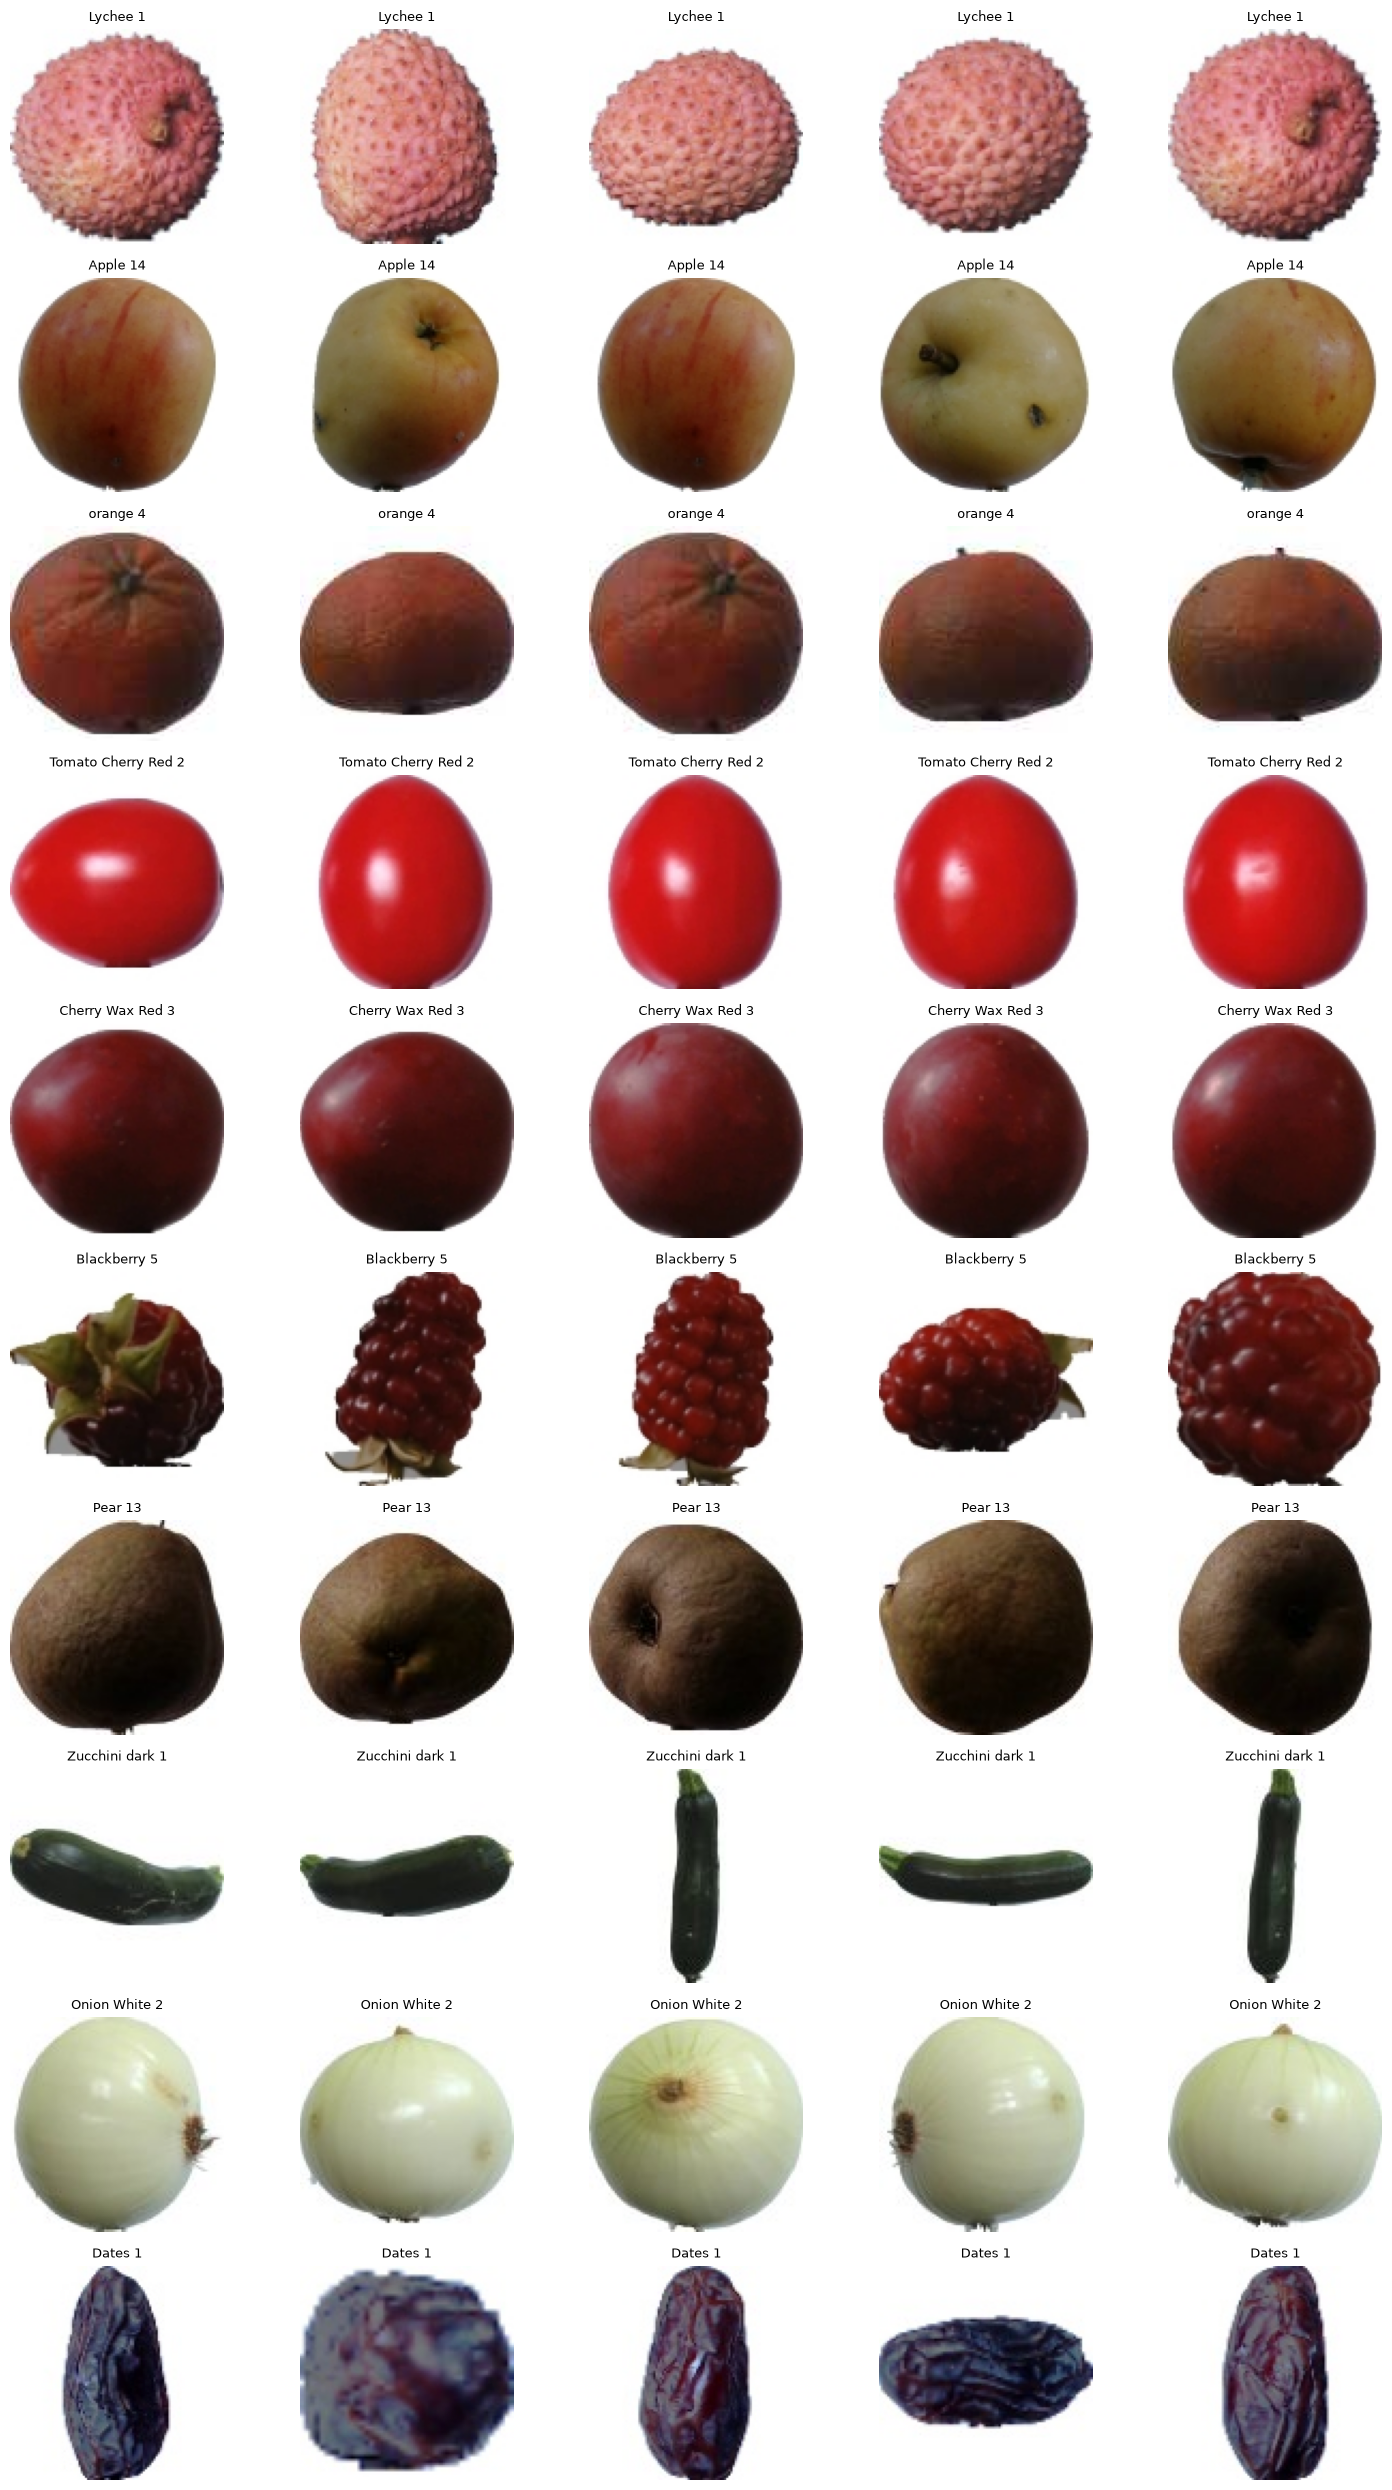

In [79]:
# Visualizando as imagens selecionadas

fig, axes = plt.subplots(10, 5, figsize=(15, 25))

for i, registro in enumerate(imagens_amostra):

    imagem = cv2.imread(str(registro["caminho"]))

    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    linha = i // 5
    coluna = i % 5

    axes[linha, coluna].imshow(imagem)

    axes[linha, coluna].set_title(registro["classe"], fontsize=9)

    axes[linha, coluna].axis("off")

plt.tight_layout()
plt.show()

### Conclusão da etapa 1.4

Foi realizada uma inspeção visual amostral de 50 imagens, distribuídas entre 10 classes selecionadas aleatoriamente do conjunto de treinamento. Todas as imagens analisadas apresentaram correspondência com seus respectivos rótulos, não sendo identificados erros evidentes de classificação ou problemas visuais significativos. Observou-se, entretanto, variabilidade na orientação, aparência, formato e iluminação dos objetos, características relevantes para o desenvolvimento do modelo de classificação. Ressalta-se que a inspeção amostral não permite garantir a ausência de inconsistências em todo o conjunto de dados.

## 1.5 - Analizando o balanciamento das classes

1. Objetivos da análise
Nesta etapa, vamos investigar:
1. Quantidade de imagens por classe.
2. Classes com maior quantidade de imagens.
3. Classes com menor quantidade de imagens.
4. Média e mediana da quantidade de imagens.
5. Desvio-padrão.
6. Distribuição da quantidade de imagens.
7. Diferenças entre treinamento e teste.
8. Existência de possíveis desequilíbrios.

### 1.5.1 - Ordenando as classes pela quantidade de imagens

In [94]:
# Classes com maior quantidade de imagens no treinamento

df_treino_ordenado = df_treino.sort_values(by="quantidade", ascending=False)
print("Classes com maior quantidade de imagens no treinamento:")
display(df_treino_ordenado.head(10))

Classes com maior quantidade de imagens no treinamento:


,classe,quantidade
111,Grape Blue 1,984
96,Cucumber 6,977
66,Cherimoya 1,972
62,Carambola 3,960
101,Dates 2,959
165,orange 4,948
192,Pear 8,936
193,Pear 9,928
173,Peach 3,927
225,Plum 3,900


**Interpretação**\
A classe Grape Blue 1 possui a maior quantidade de imagens no conjunto de treinamento, totalizando 984 imagens.

Entretanto, observa-se que as demais classes presentes no Top 10 também possuem quantidades relativamente próximas, variando de 900 a 984 imagens.

Isso significa que, embora existam diferenças na quantidade de exemplos entre as classes, as dez classes mais representadas não apresentam diferenças extremamente acentuadas entre si.

É importante destacar que essas classes representam apenas o extremo superior da distribuição. Para avaliar o balanceamento geral, precisamos compará-las com as classes que possuem menor quantidade de imagens.

In [95]:
# Classes com menor quantidade de imagens no treinamento

df_treino_ordenado_crescente = df_treino.sort_values(by="quantidade", ascending=True)
print("Classes com menor quantidade de imagens no treinamento:")
display(df_treino_ordenado_crescente.head(10))

Classes com menor quantidade de imagens no treinamento:


,classe,quantidade
277,Zucchini Green 1,144
52,Cabbage white 1,144
51,Cabbage red 1,149
88,Cucumber 1,150
63,Carrot 1,151
178,Peanut shell 1x 1,159
38,Banana 2,224
46,Blackberry 2,225
56,Caju seed 1,226
243,Raspberry 5,227


**Interpretação**\
As classes Zucchini Green 1 e Cabbage white 1 possuem a menor quantidade de imagens, com 144 imagens cada.

Observa-se que algumas classes possuem quantidades significativamente menores de exemplos do que aquelas presentes no Top 10.

Por exemplo:
- Grape Blue 1: 984 imagens.
- Zucchini Green 1: 144 imagens.
Essa diferença pode influenciar o aprendizado do modelo, pois a classe Grape Blue 1 possui aproximadamente 6,83 vezes mais imagens de treinamento do que Zucchini Green 1.

Por outro lado, todas as classes possuem uma quantidade considerável de imagens. Não encontramos classes com apenas algumas dezenas de exemplos no treinamento.

Isso é um aspecto positivo para o desenvolvimento do modelo, embora não elimine a possibilidade de diferenças de desempenho entre classes.

In [84]:
print("Estatísticas do treinamento:")
display(df_treino["quantidade"].describe())

Estatísticas do treinamento:


count    278.000000
mean     540.212230
std      171.233184
min      144.000000
25%      456.000000
50%      490.000000
75%      699.000000
max      984.000000
Name: quantidade, dtype: float64

3.1 Média \
A média indica que cada classe possui aproximadamente 540 imagens de treinamento.

Entretanto, a média não significa que todas as classes possuem essa quantidade. Há classes com 144 imagens e outras com 984 imagens.

3.2 Mediana\
A mediana é de 490 imagens.\
Isso significa que aproximadamente metade das classes possui quantidade de imagens inferior ou igual a 490, enquanto a outra metade possui quantidade superior ou igual a esse valor.

Observe que a média (540,21) é maior que a mediana (490).

Essa diferença sugere que classes com quantidades relativamente elevadas de imagens influenciam a média, elevando-a em relação à mediana.

3.3 Desvio-padrão\
O desvio-padrão foi de aproximadamente 171,23 imagens.\
Isso indica uma variabilidade considerável na quantidade de imagens entre as classes.

Para contextualizar essa variabilidade, podemos calcular o coeficiente de variação:

CV = Desvio-padrão / Média) * 100

Substituindo:

CV = (171,23 / 540,21) * 100 \
CV = 31,7\%

Isso significa que o desvio-padrão corresponde a aproximadamente 31,7% da média.

Esse valor reforça a existência de diferenças relevantes na quantidade de imagens entre as classes.\
O coeficiente de variação é uma medida complementar. Não existe um limite universal que, isoladamente, determine se um dataset está balanceado ou desbalanceado.

3.4 Quartis
Os quartis permitem compreender melhor como as quantidades estão distribuídas.
- 25%: 456 imagens.
- 50%: 490 imagens.
- 75%: 699 imagens.\
Isso significa que 50% das classes estão concentradas entre 456 e 699 imagens.

Observe, entretanto, que existe uma diferença relativamente grande entre o primeiro quartil e o terceiro quartil:\

699 - 456 = 243

Portanto, mesmo considerando apenas a região central da distribuição, existe uma variação significativa na quantidade de imagens por classe.

In [96]:
# Classes com maior quantidade de imagens no teste

df_teste_ordenado = df_teste.sort_values(by="quantidade", ascending=False)
print("Classes com maior quantidade de imagens no teste:")
display(df_teste_ordenado.head(10))

Classes com maior quantidade de imagens no teste:


,classe,quantidade
111,Grape Blue 1,328
96,Cucumber 6,325
66,Cherimoya 1,320
62,Carambola 3,320
101,Dates 2,319
165,orange 4,316
192,Pear 8,308
193,Pear 9,308
173,Peach 3,306
225,Plum 3,304


Interpretação\
As classes que possuem maior quantidade de imagens no treinamento também aparecem entre as classes mais representadas no teste.

Isso é esperado, considerando a organização original do Fruits-360, em que os conjuntos de treinamento e teste foram construídos mantendo a distribuição das classes relativamente proporcional.

Essa correspondência é importante porque evita, por exemplo, uma situação em que determinada classe tivesse muitas imagens no treinamento, mas pouquíssimas imagens no teste.

In [97]:
# Classes com menor quantidade de imagens no teste

df_teste_ordenado_crescente = df_teste.sort_values(by="quantidade", ascending=True)
print("Classes com menor quantidade de imagens no teste:")
display(df_teste_ordenado_crescente.head(10))

Classes com menor quantidade de imagens no teste:


,classe,quantidade
277,Zucchini Green 1,47
52,Cabbage white 1,47
51,Cabbage red 1,49
88,Cucumber 1,50
63,Carrot 1,50
178,Peanut shell 1x 1,52
38,Banana 2,74
243,Raspberry 5,75
56,Caju seed 1,75
46,Blackberry 2,75


Interpretação\
As classes com menor quantidade de imagens no teste correspondem, em grande parte, às classes com menor quantidade de imagens no treinamento.

Isso demonstra que a distribuição entre os conjuntos foi mantida de forma relativamente consistente.

In [85]:
print("Estatísticas do teste:")
display(df_teste["quantidade"].describe())

Estatísticas do teste:


count    278.000000
mean     179.935252
std       56.707204
min       47.000000
25%      153.000000
50%      165.000000
75%      231.000000
max      328.000000
Name: quantidade, dtype: float64

Média\
Em média, cada classe possui aproximadamente 180 imagens no conjunto de teste.
Mediana
A mediana foi de 165 imagens.

Assim como no treinamento, a média é superior à mediana, indicando que classes com maiores quantidades de imagens influenciam a média.

Desvio-padrão \
O desvio-padrão é de aproximadamente 56,70 imagens.

Calculando o coeficiente de variação:

CV = (56,70 / 179,94) * 100
CV = 31,5\%

Esse valor é muito próximo do coeficiente de variação encontrado no treinamento.

Isso reforça a semelhança da distribuição de imagens entre os dois conjuntos.

### 1.5.2 - Comparando a quantidade de imagens entre treinamento e teste
 
Como os conjuntos já estão separados, podemos criar um único DataFrame para facilitar a comparação.

Utilizaremos merge().

In [98]:
# Comparando as quantidades de imagens por classe

df_comparacao = pd.merge(df_treino, df_teste, 
                         on="classe", suffixes=("_treino", "_teste"))
print("Quantidade de imagens por classe:")
display(df_comparacao.head())

Quantidade de imagens por classe:


,classe,quantidade_treino,quantidade_teste
0,Almonds 1,232,77
1,Apple 10,699,231
2,Apple 11,430,142
3,Apple 12,466,154
4,Apple 13,699,235


In [99]:
# Calculando a proporção de treinamento e teste

df_comparacao["total"] = (
    df_comparacao["quantidade_treino"] +
    df_comparacao["quantidade_teste"]
)

df_comparacao["proporcao_treino"] = (
    df_comparacao["quantidade_treino"] /
    df_comparacao["total"]
)

df_comparacao["proporcao_teste"] = (
    df_comparacao["quantidade_teste"] /
    df_comparacao["total"]
)
print("Proporção de treinamento e teste:")
display(df_comparacao.head())

Proporção de treinamento e teste:


,classe,quantidade_treino,quantidade_teste,total,proporcao_treino,proporcao_teste
0,Almonds 1,232,77,309,0.750809,0.249191
1,Apple 10,699,231,930,0.751613,0.248387
2,Apple 11,430,142,572,0.751748,0.248252
3,Apple 12,466,154,620,0.751613,0.248387
4,Apple 13,699,235,934,0.748394,0.251606


Interpretação\
A distribuição das imagens entre treinamento e teste apresenta consistência.

Isso significa que, em geral, a quantidade de imagens de cada classe foi dividida de forma proporcional entre os dois conjuntos.

Esse comportamento é favorável para a avaliação do modelo, pois reduz a possibilidade de diferenças significativas na distribuição das classes entre treinamento e teste.

### 1.5.3 - Visualizando a distribução das quantidades

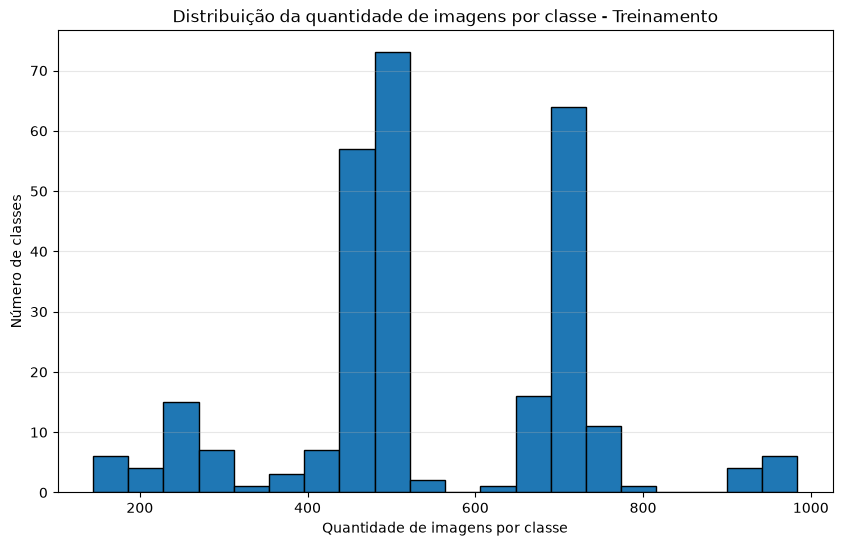

In [88]:
# Histograma do conjunto de treinamento
plt.figure(figsize=(10, 6))

plt.hist(
    df_treino["quantidade"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribuição da quantidade de imagens por classe - Treinamento")
plt.xlabel("Quantidade de imagens por classe")
plt.ylabel("Número de classes")

plt.grid(axis="y", alpha=0.3)

plt.show()

Interpretação \
O histograma demonstra que o dataset não possui uma distribuição uniforme de imagens entre as classes.

Existem grupos de classes com quantidades semelhantes de exemplos, mas esses grupos apresentam diferentes níveis de representatividade.

Isso indica que algumas classes terão mais exemplos disponíveis para treinamento do modelo do que outras.

Uma observação importante\
O gráfico não apresenta uma distribuição simples, como uma distribuição normal perfeitamente simétrica.

Existem concentrações em diferentes intervalos, sugerindo uma distribuição multimodal ou agrupada.

Entretanto, não precisamos afirmar formalmente que a distribuição é multimodal apenas com base na aparência do histograma. Para o nosso objetivo, a observação mais importante é que a quantidade de imagens varia consideravelmente entre as classes.

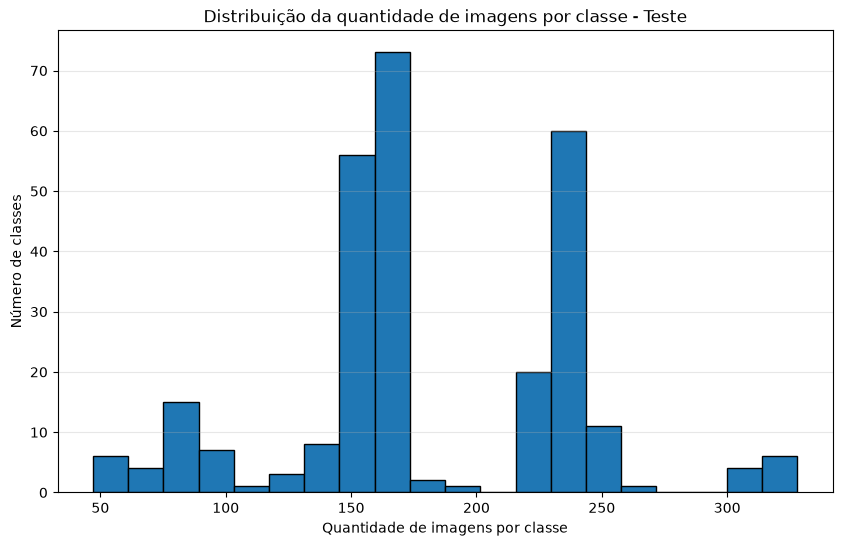

In [89]:
# Histograma do conjunto de teste
plt.figure(figsize=(10, 6))

plt.hist(
    df_teste["quantidade"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribuição da quantidade de imagens por classe - Teste")
plt.xlabel("Quantidade de imagens por classe")
plt.ylabel("Número de classes")

plt.grid(axis="y", alpha=0.3)

plt.show()

Interpretação\
A distribuição do teste acompanha o comportamento da distribuição do treinamento.

Isso é importante porque permite avaliar o desempenho do modelo em todas as classes, incluindo aquelas que possuem menos imagens disponíveis.

Entretanto, as classes menos representadas terão menor quantidade de exemplos para avaliação.

Consequentemente, métricas calculadas para essas classes podem apresentar maior variabilidade, pois cada erro representa uma proporção maior do total de exemplos daquela classe.

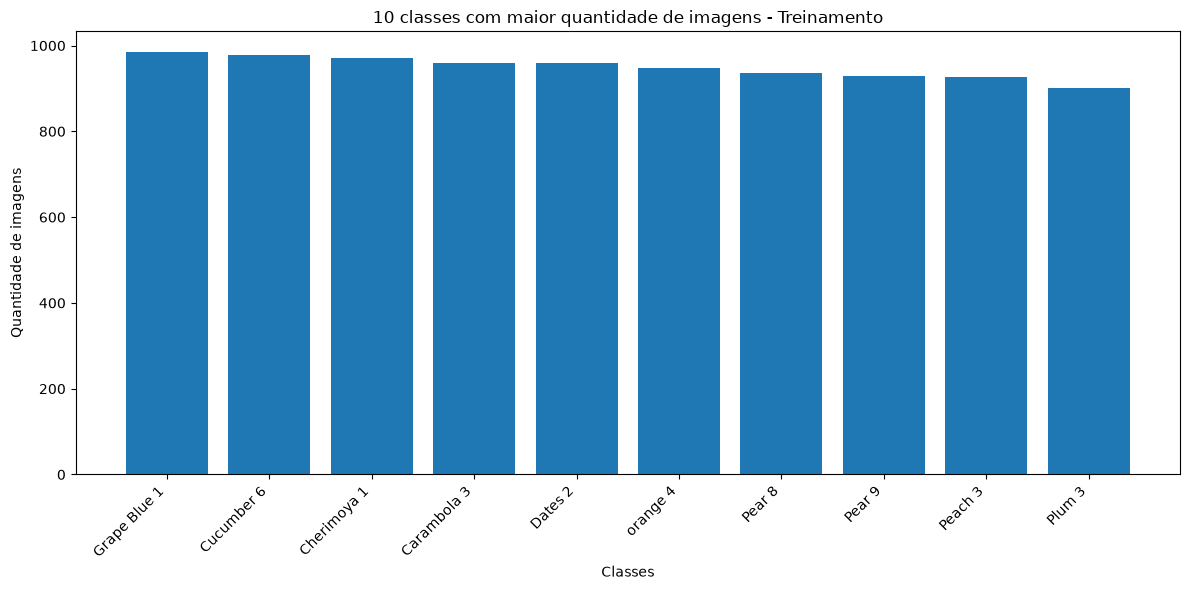

In [90]:
# Selecionando as 10 classes com maior quantidade de imagens

top_10 = df_treino_ordenado.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10["classe"],
    top_10["quantidade"]
)

plt.title("10 classes com maior quantidade de imagens - Treinamento")
plt.xlabel("Classes")
plt.ylabel("Quantidade de imagens")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

Interpretação\
O gráfico mostra que o grupo das classes mais representadas é relativamente homogêneo.

A diferença entre a maior classe e a décima classe é:

984 - 900 = 84

Ou seja, mesmo entre as dez classes com maior quantidade de imagens, a diferença é de apenas 84 imagens.

O maior desequilíbrio não ocorre necessariamente dentro do Top 10, mas principalmente quando comparamos as classes mais representadas com aquelas menos representadas.

### Identificando classes mais discrepantes

Podemos calcular a diferença entre a maior e a menor quantidade de imagens.

In [91]:
maior_quantidade = df_treino["quantidade"].max()

menor_quantidade = df_treino["quantidade"].min()

diferenca = maior_quantidade - menor_quantidade

print("Maior quantidade:", maior_quantidade)
print("Menor quantidade:", menor_quantidade)
print("Diferença:", diferenca)

Maior quantidade: 984
Menor quantidade: 144
Diferença: 840


Portanto, existem 840 imagens de diferença entre a classe mais representada e a menos representada no treinamento.

Essa diferença evidencia que as classes não possuem a mesma quantidade de imagens.

In [92]:
razao = maior_quantidade / menor_quantidade

print("Razão entre a maior e a menor classe:", razao)

Razão entre a maior e a menor classe: 6.833333333333333


Isso significa que a classe com maior quantidade de imagens possui aproximadamente 6,83 vezes mais exemplos do que a classe com menor quantidade.

Essa é uma forma bastante intuitiva de demonstrar o desequilíbrio existente.

Porém, precisamos interpretar isso com cuidado:
Uma razão de 6,83 não significa automaticamente que o dataset seja inadequado ou extremamente desbalanceado. Ela demonstra que existe uma diferença significativa entre os extremos, mas todas as 278 classes ainda possuem uma quantidade considerável de imagens.

### Conclusão da Etapa 1.5

A análise do balanceamento demonstrou que o conjunto de dados possui 278 classes, com quantidades distintas de imagens. No conjunto de treinamento, a quantidade varia entre 144 e 984 imagens por classe, enquanto no conjunto de teste varia entre 47 e 328 imagens.

As estatísticas descritivas indicaram médias de aproximadamente 540 imagens por classe no treinamento e 180 no teste. Os coeficientes de variação foram de aproximadamente 31,7% e 31,5%, respectivamente, evidenciando variabilidade semelhante na distribuição dos dados.

Os histogramas demonstraram que a distribuição da quantidade de imagens por classe não é uniforme, apresentando concentrações em diferentes intervalos. Além disso, a classe mais representada possui aproximadamente 6,83 vezes a quantidade de imagens da classe menos representada no treinamento.

Apesar dessas diferenças, todas as classes possuem uma quantidade considerável de exemplos, não sendo identificadas classes com representação extremamente reduzida. Também foi observada uma divisão proporcional entre treinamento e teste, próxima de 75% e 25%, respectivamente, para a maioria das classes.

Dessa forma, conclui-se que o dataset apresenta um desequilíbrio moderado na quantidade de imagens entre as classes, sendo importante considerar essa característica durante o treinamento e a avaliação dos modelos, especialmente na interpretação das métricas de desempenho individuais por classe.

## 1.6 - presentação de exemplos das imagens e principais dificuldades do problema

Objetivo\
Identificar as principais dificuldades que um modelo poderá enfrentar ao classificar as imagens.

Entre elas, podemos investigar:\
A. Classes visualmente semelhantes
Exemplos:\
- Diferentes variedades de maçãs.
- Diferentes variedades de peras.
- Diferentes variedades de cerejas.
- Frutas com cores e formatos semelhantes.\

Um modelo poderá ter dificuldade em distinguir classes cujas diferenças são sutis.

B. Variações dentro da mesma classe
Imagens da mesma classe podem apresentar:\
- Diferentes orientações.
- Formatos ligeiramente diferentes.
- Variações de iluminação.
- Diferentes posições.
- Diferenças de textura.
- Pequenas variações de tamanho.

C. Diferenças de cor
A cor pode ser um importante atributo para classificação, mas pode variar devido à iluminação, maturação e aparência natural dos objetos.\

D. Textura
Algumas frutas apresentam texturas muito características, enquanto outras possuem superfícies relativamente lisas.

O modelo poderá precisar aprender essas características para distinguir classes.

E. Formato
O formato pode ser uma característica relevante, principalmente quando classes apresentam cores semelhantes, mas formas diferentes.

### 1.6.1 — Selecionar imagens para análise visual

In [100]:
# Visualizando classes relacionadas a maçãs

classes_maça = [
    classe for classe in classes_treino
    if "Apple" in classe
]

print(classes_maça)

['Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7', 'Apple 8', 'Apple 9', 'Apple Braeburn 1', 'Apple Crimson Snow 1', 'Apple Golden 1', 'Apple Golden 2', 'Apple Golden 3', 'Apple Granny Smith 1', 'Apple Pink Lady 1', 'Apple Red 1', 'Apple Red 2', 'Apple Red 3', 'Apple Red Delicious 1', 'Apple Red Yellow 1', 'Apple Red Yellow 2']


In [101]:
classes_pera = [
    classe for classe in classes_treino
    if "Pear" in classe
]

print(classes_pera)

['Pear 1', 'Pear 10', 'Pear 11', 'Pear 12', 'Pear 13', 'Pear 14', 'Pear 2', 'Pear 3', 'Pear 5', 'Pear 6', 'Pear 7', 'Pear 8', 'Pear 9', 'Pear Abate 1', 'Pear Forelle 1', 'Pear Kaiser 1', 'Pear Monster 1', 'Pear Red 1', 'Pear Stone 1', 'Pear Williams 1']


In [105]:
classes_cereja = [
    classe for classe in classes_treino
    if classe.startswith("Cherry")
]

print(classes_cereja)

['Cherry 1', 'Cherry 2', 'Cherry 3', 'Cherry 4', 'Cherry 5', 'Cherry Rainier 1', 'Cherry Rainier 2', 'Cherry Rainier 3', 'Cherry Sour 1', 'Cherry Wax 1', 'Cherry Wax 2', 'Cherry Wax Black 1', 'Cherry Wax Red 1', 'Cherry Wax Red 2', 'Cherry Wax Red 3', 'Cherry Wax Yellow 1']


### 1.6.2 — Visualizar diferentes classes de um mesmo grupo

In [103]:
# Escolha manual de classes para comparação

classes_visualizacao = [
    "Apple Braeburn 1",
    "Apple Granny Smith 1",
    "Apple Golden 1",
    "Apple Red 1",
    "Apple Pink Lady 1"
]

imagens_visualizacao = []

for classe in classes_visualizacao:

    pasta = caminho_treino / classe

    imagens = list(pasta.glob("*.jpg"))

    imagem_selecionada = random.choice(imagens)

    imagens_visualizacao.append({
        "classe": classe,
        "caminho": imagem_selecionada
    })

### 1.6.3 — Seleção das classes para análise visual

In [ ]:
# Selecionar uma imagem aleatória de cada classe

def selecionar_imagens(classes, caminho_base):
    imagens_selecionadas = []
    for classe in classes:
        pasta = caminho_base / classe
        imagens = list(pasta.glob("*.jpg"))
        imagem = random.choice(imagens)
        imagens_selecionadas.append({
            "classe": classe,
            "caminho": imagem
        })

    return imagens_selecionadas

In [ ]:
# Criar os grupos de análise

classes_macas = [
    "Apple Braeburn 1",
    "Apple Granny Smith 1",
    "Apple Golden 1",
    "Apple Pink Lady 1",
    "Apple Red Delicious 1"
]

classes_peras = [
    "Pear Abate 1",
    "Pear Forelle 1",
    "Pear Kaiser 1",
    "Pear Williams 1",
    "Pear Red 1"
]

classes_cerejas = [
    "Cherry 1",
    "Cherry Rainier 1",
    "Cherry Sour 1",
    "Cherry Wax Red 1",
    "Cherry Wax Yellow 1"
]

# Selecionando as imagens 

imagens_macas = selecionar_imagens(
    classes_macas,
    caminho_treino
)

imagens_peras = selecionar_imagens(
    classes_peras,
    caminho_treino
)

imagens_cerejas = selecionar_imagens(
    classes_cerejas,
    caminho_treino
)

In [ ]:
# Criar uma função para visualizar as imagens

def visualizar_imagens(imagens_selecionadas, titulo):

    fig, axes = plt.subplots(
        1,
        len(imagens_selecionadas),
        figsize=(15, 4)
    )

    fig.suptitle(titulo, fontsize=16)

    for i, registro in enumerate(imagens_selecionadas):

        imagem = cv2.imread(str(registro["caminho"]))

        imagem = cv2.cvtColor(
            imagem,
            cv2.COLOR_BGR2RGB
        )

        axes[i].imshow(imagem)

        axes[i].set_title(
            registro["classe"],
            fontsize=9
        )

        axes[i].axis("off")

    plt.tight_layout()

    plt.show()

### Visualizando as maçãs

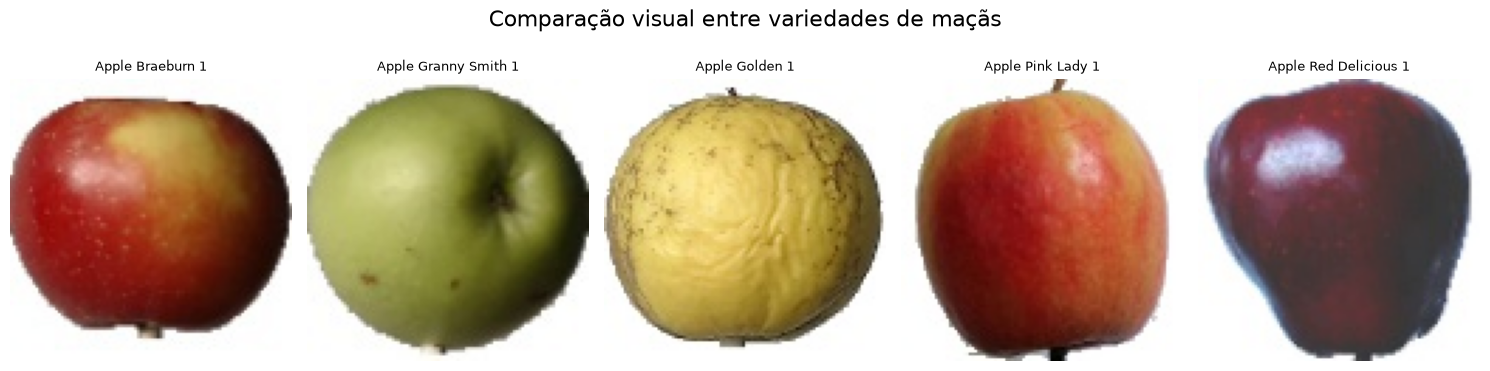

In [109]:
visualizar_imagens(
    imagens_macas,
    "Comparação visual entre variedades de maçãs"
)

### Visualizando as peras

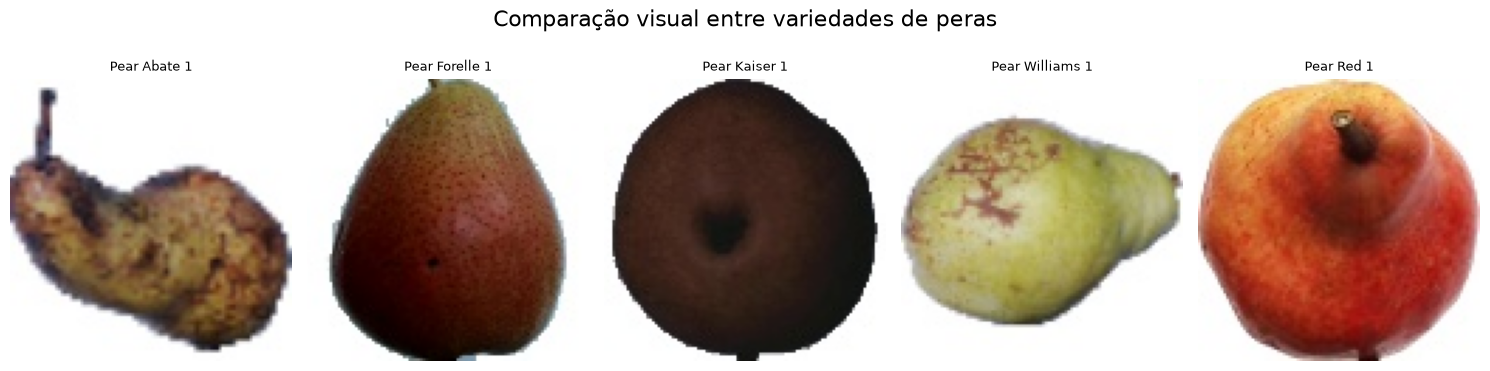

In [110]:
visualizar_imagens(
    imagens_peras,
    "Comparação visual entre variedades de peras"
)

### Visualizando as cerejas

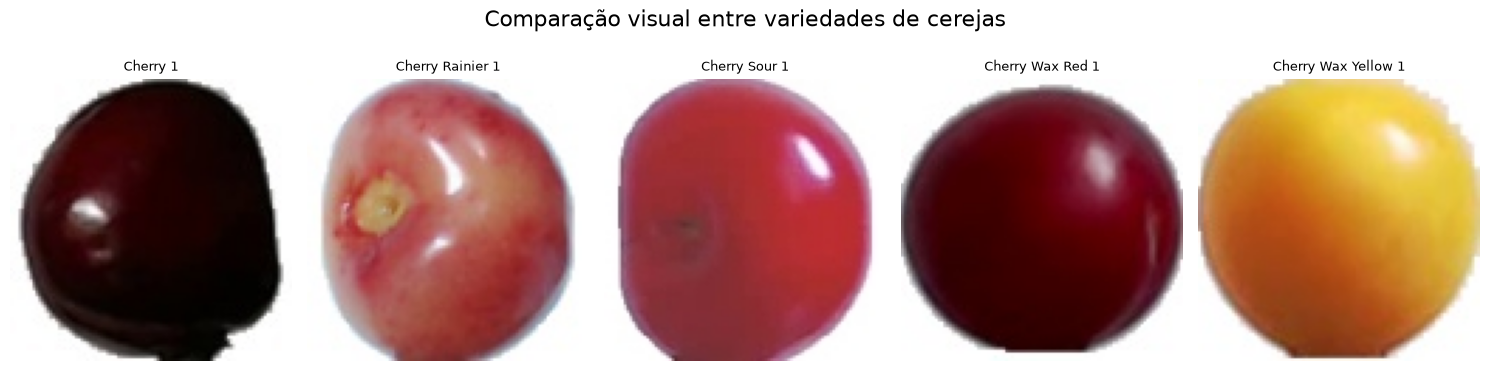

In [111]:
visualizar_imagens(
    imagens_cerejas,
    "Comparação visual entre variedades de cerejas"
)

### Análise adicional: visualizar várias imagens da mesma classe

O que essa análise demonstra?\
Ela permite avaliar a variabilidade intraclasse.

Em classificação de imagens, temos dois tipos importantes de variação:

Variabilidade intraclasse: diferenças entre imagens que pertencem à mesma classe.

Variabilidade interclasse: diferenças entre imagens pertencentes a classes distintas.

Idealmente, o modelo precisa aprender características que sejam:
- Consistentes dentro de uma classe.
- Diferentes entre classes.
Essa é uma das questões centrais do aprendizado de máquina aplicado à visão computacional.

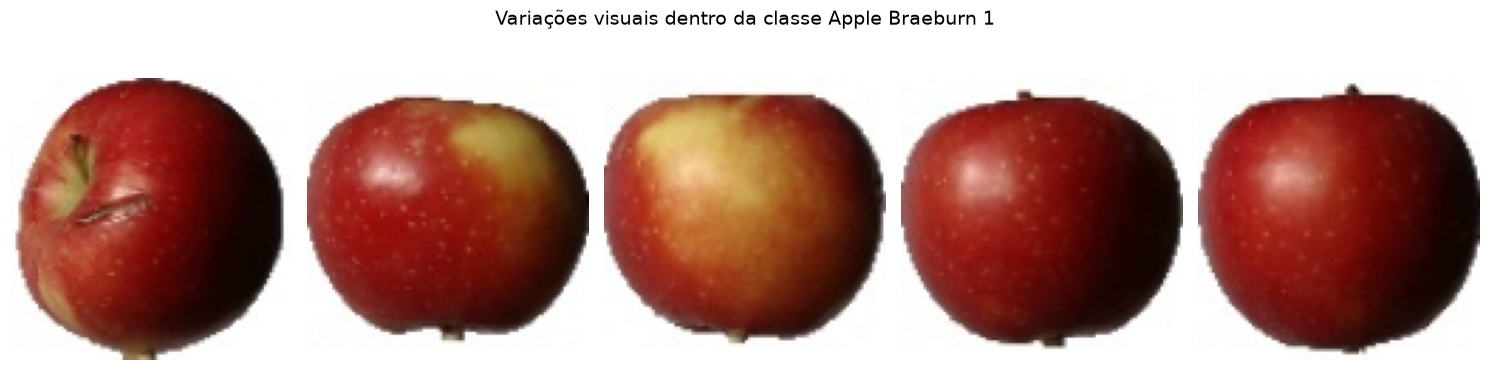

In [112]:
classe = "Apple Braeburn 1"
pasta = caminho_treino / classe
imagens = list(pasta.glob("*.jpg"))
imagens_amostra = random.sample(imagens, 5)

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

fig.suptitle(
    f"Variações visuais dentro da classe {classe}",
    fontsize=14
)

for i, caminho_imagem in enumerate(imagens_amostra):

    imagem = cv2.imread(str(caminho_imagem))

    imagem = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(imagem)

    axes[i].axis("off")

plt.tight_layout()

plt.show()

## 1.7 - Divisão dos dados e prevenção de vazamento de dados (Data Leakage)

O objetivo é definir quais imagens serão utilizadas no treinamento e quais serão utilizadas na avaliação, garantindo que o modelo seja avaliado de maneira justa.

In [113]:
# Verificando hashes compartilhados entre treinamento e teste

hashes_treino = set(df_hashes_treino["hash"])
hashes_teste = set(df_hashes_teste["hash"])
hashes_comuns = hashes_treino.intersection(hashes_teste)
print("Quantidade de hashes compartilhados:", len(hashes_comuns))

Quantidade de hashes compartilhados: 0


Resultado igual a zero: não foram encontradas duplicatas exatas entre treinamento e teste.

### 1.7.2 — Verificar possíveis imagens relacionadas pelo nome

In [114]:
# Investigando nomes de arquivos relacionados

pasta = caminho_treino / "Apple Braeburn 1"

imagens = list(pasta.glob("*.jpg"))

for imagem in imagens[:20]:

    print(imagem.name)

0_100.jpg
100_100.jpg
101_100.jpg
102_100.jpg
103_100.jpg
104_100.jpg
105_100.jpg
106_100.jpg
107_100.jpg
108_100.jpg
109_100.jpg
10_100.jpg
110_100.jpg
111_100.jpg
112_100.jpg
113_100.jpg
114_100.jpg
115_100.jpg
116_100.jpg
117_100.jpg


### 1.7.3 - Definir a estratégia de utilização dos dados

Preservar a divisão original do Fruits-360 e selecionar aleatoriamente 25% das imagens de cada conjunto, mantendo a proporção de imagens por classe.

Isso permite reduzir o custo computacional, mantendo a estrutura original dos dados.

1.7.3 - Criar um DataFrame com os caminhos das imagens

Até agora, seus DataFrames contêm a quantidade de imagens por classe.

Agora precisamos criar uma estrutura que contenha uma linha para cada imagem, permitindo selecionar amostras aleatórias.

In [115]:
# Criando uma estrutura com os caminhos das imagens

def criar_dataframe_imagens(caminho_base):
    registros = []
    for pasta in caminho_base.iterdir():
        if pasta.is_dir():
            for imagem in pasta.glob("*.jpg"):
                registros.append({
                    "classe": pasta.name,
                    "caminho": imagem
                })
    df = pd.DataFrame(registros)
    return df

In [116]:
df_imagens_treino = criar_dataframe_imagens(caminho_treino)
df_imagens_teste = criar_dataframe_imagens(caminho_teste)

print("Treinamento:")
print(df_imagens_treino.shape)

print("\nTeste:")
print(df_imagens_teste.shape)

Treinamento:
(150179, 2)

Teste:
(50022, 2)


In [117]:
display(df_imagens_treino.head())

,classe,caminho
0,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_0_100...
1,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_100_1...
2,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_101_1...
3,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_102_1...
4,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_104_1...


### 1.7.5 — Selecionar 25% das imagens

Agora vamos selecionar uma amostra aleatória de 25% de cada classe.

É importante fazer a seleção separadamente para treinamento e teste.

In [118]:
# Selecionando 25% das imagens de treinamento

df_treino_reduzido = (
    df_imagens_treino
    .groupby("classe", group_keys=False)
    .sample(frac=0.25, random_state=42)
)

print("Quantidade de imagens selecionadas:", len(df_treino_reduzido))

Quantidade de imagens selecionadas: 37528


In [119]:
# Selecionando 25% das imagens de teste

df_teste_reduzido = (
    df_imagens_teste
    .groupby("classe", group_keys=False)
    .sample(frac=0.25, random_state=42)
)

print("Quantidade de imagens selecionadas:", len(df_teste_reduzido))

Quantidade de imagens selecionadas: 12528


### 1.7.6 — Verificar a quantidade selecionada

In [120]:
print("===== DATASET REDUZIDO =====")

print("\nTreinamento:")
print(df_treino_reduzido.shape)

print("\nTeste:")
print(df_teste_reduzido.shape)

print("\nTotal:")
print(
    len(df_treino_reduzido) +
    len(df_teste_reduzido)
)

===== DATASET REDUZIDO =====

Treinamento:
(37528, 2)

Teste:
(12528, 2)

Total:
50056


### 1.7.7 — Verificar se todas as classes foram preservadas

In [122]:
classes_reduzidas_treino = set(
    df_treino_reduzido["classe"]
)

classes_reduzidas_teste = set(
    df_teste_reduzido["classe"]
)

print("Classes no treinamento:", len(classes_reduzidas_treino))
print("Classes no teste:", len(classes_reduzidas_teste))

# verificamos se as classes são iguais
print(
    "Classes ausentes no treinamento:",
    set(classes_treino) - classes_reduzidas_treino
)

print(
    "Classes ausentes no teste:",
    set(classes_teste) - classes_reduzidas_teste
)

Classes no treinamento: 278
Classes no teste: 278
Classes ausentes no treinamento: set()
Classes ausentes no teste: set()


### 1.7.8 — Verificar o balanceamento após a redução

In [123]:
contagem_reduzida_treino = (
    df_treino_reduzido["classe"]
    .value_counts()
    .sort_index()
)

contagem_reduzida_teste = (
    df_teste_reduzido["classe"]
    .value_counts()
    .sort_index()
)

print("Estatísticas do treinamento reduzido:")

print(contagem_reduzida_treino.describe())

print("\nEstatísticas do teste reduzido:")

print(contagem_reduzida_teste.describe())

Estatísticas do treinamento reduzido:
count    278.000000
mean     134.992806
std       42.835930
min       36.000000
25%      114.000000
50%      122.000000
75%      175.000000
max      246.000000
Name: count, dtype: float64

Estatísticas do teste reduzido:
count    278.000000
mean      45.064748
std       14.158060
min       12.000000
25%       38.000000
50%       41.500000
75%       58.000000
max       82.000000
Name: count, dtype: float64


### 1.7.9 — Visualizar a distribuição após a redução

#### Treinamento


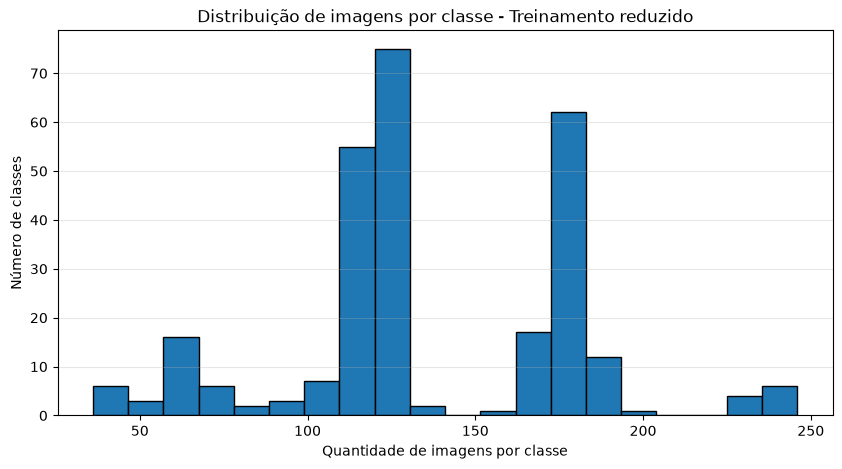

In [124]:
plt.figure(figsize=(10, 5))

plt.hist(
    contagem_reduzida_treino,
    bins=20,
    edgecolor="black"
)

plt.title("Distribuição de imagens por classe - Treinamento reduzido")

plt.xlabel("Quantidade de imagens por classe")

plt.ylabel("Número de classes")

plt.grid(axis="y", alpha=0.3)

plt.show()

#### Teste

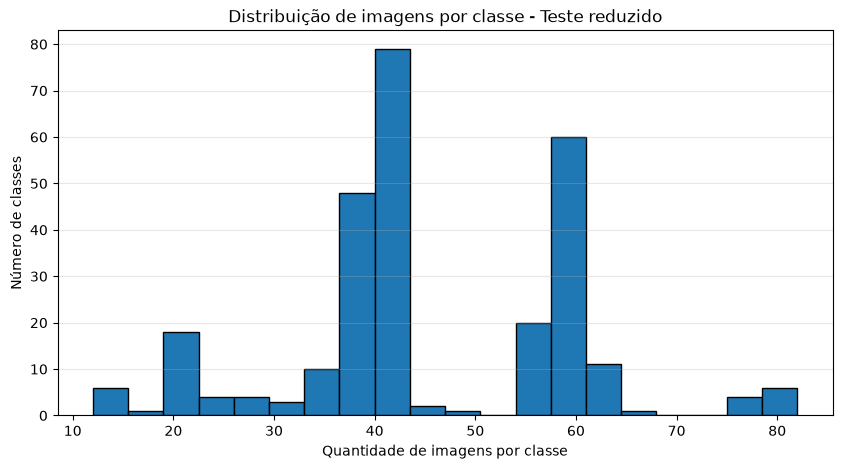

In [125]:
plt.figure(figsize=(10, 5))

plt.hist(
    contagem_reduzida_teste,
    bins=20,
    edgecolor="black"
)

plt.title("Distribuição de imagens por classe - Teste reduzido")

plt.xlabel("Quantidade de imagens por classe")

plt.ylabel("Número de classes")

plt.grid(axis="y", alpha=0.3)

plt.show()

### 1.7.10 — Salvar a seleção

É importante salvar os caminhos das imagens selecionadas.

Assim, não precisaremos selecionar novamente as imagens a cada execução.

In [126]:
df_treino_reduzido.to_csv(
    "treino_reduzido.csv",
    index=False
)

df_teste_reduzido.to_csv(
    "teste_reduzido.csv",
    index=False
)